In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad

In [2]:
def V_double_well(x, U0, x0, sigma):
    v = (
        4 * U0 / x0**4 * x**3 - 4 * U0 / x0**2 * x + sigma / (2 * x0)
    )  # Double-well potential
    return v


def integrand(x, U0, x0, beta, sigma):
    v = np.exp(
        -beta * (U0 * (1 - (x / x0) ** 2) ** 2 + sigma * x / (2 * x0))
    )  # integrand function
    return v


######## Paraemters
gamma = 1  # Coupling constant
beta = 1  # Inverse temperature, i.e. T=1/beta
U0 = 4  # Depth of the well
x0 = 1  # Basin of the well
sigma = 0  # Asymmetry of the well
dt = 0.001  # Step-size of the SDE solver
delta_t = 0.2  # Step-size of the temporally coarse-grained path
batch = 10_000  # Batch size
sec_length = 400  # Length of the input sequence
I = quad(integrand, -4, 4, args=(U0, x0, beta, sigma))


### SDE solver (EM scheme),
Time = 4 * delta_t * sec_length
print(Time)
length = int(Time / dt) + 1
t = np.linspace(0, Time, length)  # define time axis
gap = int(delta_t / dt)
t_store = t[0:-1:gap]
p_store = np.zeros([t_store.size + 1, batch])
q_store = np.zeros([t_store.size + 1, batch])
p = np.zeros((2, batch))
q = np.zeros((2, batch))

320.0


In [3]:
# solve SDE
j = 1
for i in range(1, length):
    q[1, :] = q[0, :] + p[0, :] * dt
    p[1, :] = (
        p[0, :]
        + (-V_double_well(q[0, :], U0, x0, sigma) - gamma * p[0, :]) * dt
        + np.random.randn(1, batch) * np.sqrt(2 * dt * gamma / beta)
    )
    if i % gap == 0:
        p_store[j, :] = p[1, :]
        q_store[j, :] = q[1, :]
        j = j + 1
    p[0, :] = p[1, :]
    q[0, :] = q[1, :]

(-1.5, 1.5)

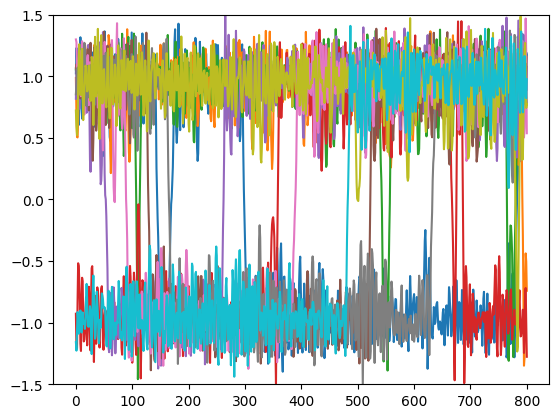

In [5]:
for i in range(60, 70):
    plt.plot(q_store[800:, i])
plt.ylim([-1.5, 1.5])

(-1.5, 1.5)

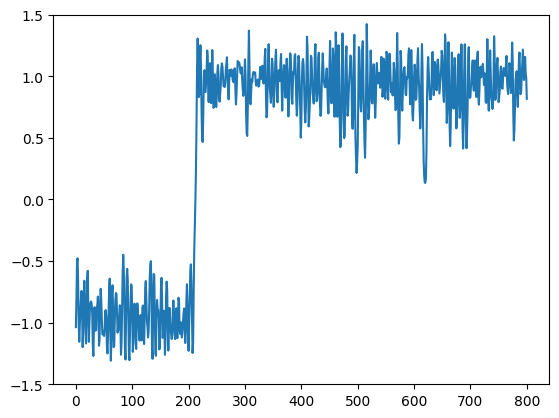

In [6]:
plt.plot(q_store[800:, 52])
plt.ylim([-1.5, 1.5])

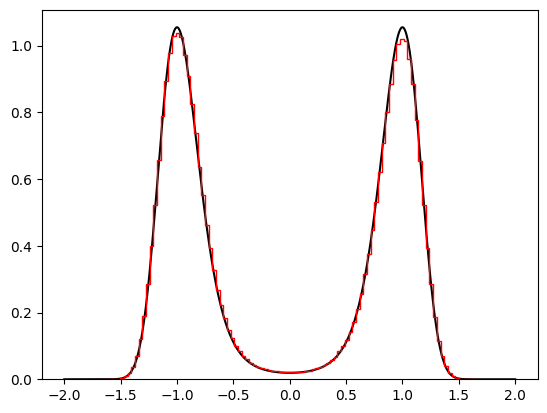

In [8]:
x = np.linspace(-2, 2, 1001)
I = quad(integrand, -10, 10, args=(U0, x0, beta, sigma))
pdf = np.exp(-beta * (U0 * (1 - (x / x0) ** 2) ** 2 + sigma * x / (2 * x0))) / I[0]

plt.plot(x, pdf, "k-")
K = 100
increment = 200
plt.hist(
    q_store[K : K + increment, :].flatten(),
    bins=100,
    density=True,
    histtype="step",
    linestyle="-",
    color="r",
)
plt.show()

In [9]:
burnin = 800
q_store = q_store[burnin:, :]
print(p_store.shape, q_store.shape)

(1601, 10000) (801, 10000)


In [ ]:
trajs = q_store.copy().T

trajs_train = trajs[:5_000, :]
trajs_test = trajs[5_000:, :]

In [ ]:
m = 10
Xs = []
dXs = []
for i in range(m, 101):
    Xs += [trajs_train[:, i - m : i]]
    dXs += [trajs_train[:, i] - trajs_train[:, i - 1]]

Xs = np.stack(Xs, axis=0)
dXs = np.stack(dXs, axis=0)

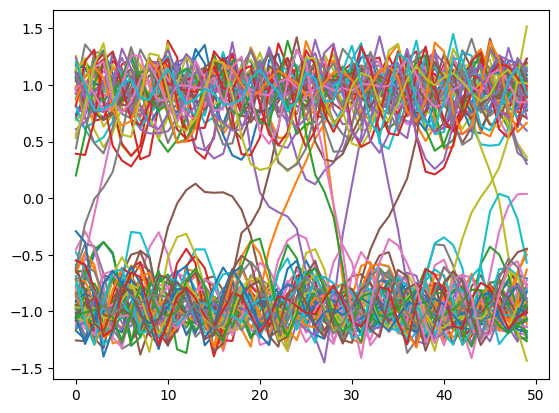

In [ ]:
for i in range(100):
    plt.plot(trajs_test[i, :50])
plt.show()

In [ ]:
import scipy.io as sio

In [ ]:
sio.savemat(
    "./data_m_10.mat",
    {
        "trajs_train": trajs_train,
        "trajs_test": trajs_test,
        "trajs": trajs,
        "Xs": Xs,
        "dXs": dXs,
        "m": m,
    },
)